# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [28]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## Exploratory Data Analysis  
- Load in the cleaned data

In [29]:
pd.set_option("display.max_columns", None)

# Load cleaned data from Part 1
data_path = Path("data")

aviation = pd.read_csv(
    data_path / "AviationData_Cleaned.csv",
    low_memory=False
)

# Inspect the dataset
print("Dataset shape:", aviation.shape)

display(aviation.head())

aviation.info()

Dataset shape: (71317, 34)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,Injury.Severity,Aircraft.damage,Aircraft.Category,Registration.Number,Make,Model,Amateur.Built,Number.of.Engines,Engine.Type,FAR.Description,Purpose.of.flight,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.People,Total.Fatal.Serious.Injuries,Fatal.Serious.Injury.Rate,Aircraft.Destroyed,Make.Model
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,Non-Fatal,SUBSTANTIAL,NaN,N1296M,CESSNA,182P,No,1.0,RECIPROCATING,NaN,PERSONAL,0.0,0.0,1.0,3.0,VMC,APPROACH,Probable Cause,NaN,4.0,0.0,0.0,0.0,CESSNA 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,Non-Fatal,SUBSTANTIAL,NaN,N2639C,CESSNA,182RG,No,1.0,RECIPROCATING,NaN,PERSONAL,0.0,0.0,0.0,2.0,VMC,LANDING,Probable Cause,NaN,2.0,0.0,0.0,0.0,CESSNA 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,Non-Fatal,SUBSTANTIAL,NaN,N58664,CESSNA,182P,No,1.0,RECIPROCATING,NaN,PERSONAL,0.0,0.0,0.0,1.0,VMC,TAKEOFF,Probable Cause,NaN,1.0,0.0,0.0,0.0,CESSNA 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,Non-Fatal,SUBSTANTIAL,NaN,N3084R,PIPER,PA-28R-200,No,1.0,RECIPROCATING,NaN,PERSONAL,0.0,0.0,2.0,0.0,VMC,APPROACH,Probable Cause,NaN,2.0,0.0,0.0,0.0,PIPER PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,Non-Fatal,SUBSTANTIAL,NaN,N89399,CESSNA,140,No,1.0,RECIPROCATING,NaN,INSTRUCTIONAL,0.0,0.0,0.0,2.0,VMC,LANDING,Probable Cause,NaN,2.0,0.0,0.0,0.0,CESSNA 140


<class 'pandas.DataFrame'>
RangeIndex: 71317 entries, 0 to 71316
Data columns (total 34 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Event.Id                      71317 non-null  str    
 1   Investigation.Type            71317 non-null  str    
 2   Accident.Number               71317 non-null  str    
 3   Event.Date                    71317 non-null  str    
 4   Location                      71268 non-null  str    
 5   Country                       71122 non-null  str    
 6   Latitude                      26334 non-null  str    
 7   Longitude                     26329 non-null  str    
 8   Airport.Code                  40209 non-null  str    
 9   Airport.Name                  42082 non-null  str    
 10  Injury.Severity               70433 non-null  str    
 11  Aircraft.damage               68609 non-null  str    
 12  Aircraft.Category             21897 non-null  str    
 13  Registration

In [30]:
# Columns required for the analysis
required_columns = [
    "Make",
    "Model",
    "Make.Model",
    "Total.People",
    "Total.Fatal.Serious.Injuries"
]

missing_columns = [
    col for col in required_columns
    if col not in aviation.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Inspect missing values in key columns
display(
    aviation[required_columns]
    .isna()
    .sum()
)

# Summary statistics
display(
    aviation[
        [
            "Total.People",
            "Total.Fatal.Serious.Injuries"
        ]
    ].describe()
)

Make                                0
Model                               0
Make.Model                          0
Total.People                    11860
Total.Fatal.Serious.Injuries    11456
dtype: int64

,Total.People,Total.Fatal.Serious.Injuries
count,59457.000000,59861.000000
mean,6.661386,0.826348
std,29.409060,5.507541
min,0.000000,0.000000
25%,1.000000,0.000000
50%,2.000000,0.000000
75%,3.000000,1.000000
max,576.000000,295.000000


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [31]:
# Ensure the relevant columns are numeric
aviation["Total.People"] = pd.to_numeric(
    aviation["Total.People"],
    errors="coerce"
)

aviation["Total.Fatal.Serious.Injuries"] = pd.to_numeric(
    aviation["Total.Fatal.Serious.Injuries"],
    errors="coerce"
)

# Keep records with valid denominators and injury counts
valid_records = (
    aviation["Total.People"].gt(0)
    & aviation["Total.People"].notna()
    & aviation["Total.Fatal.Serious.Injuries"].notna()
    & aviation["Total.Fatal.Serious.Injuries"].ge(0)
    & aviation["Total.Fatal.Serious.Injuries"].le(
        aviation["Total.People"]
    )
)

aviation = aviation.loc[valid_records].copy()

# Calculate the fraction of people who sustained fatal or serious injuries
aviation["Fatal.Serious.Injury.Fraction"] = (
    aviation["Total.Fatal.Serious.Injuries"]
    / aviation["Total.People"]
)

# Inspect the result
display(
    aviation[
        [
            "Make",
            "Model",
            "Total.People",
            "Total.Fatal.Serious.Injuries",
            "Fatal.Serious.Injury.Fraction"
        ]
    ].head(10)
)

display(
    aviation["Fatal.Serious.Injury.Fraction"].describe()
)

,Make,Model,Total.People,Total.Fatal.Serious.Injuries,Fatal.Serious.Injury.Fraction
0,CESSNA,182P,4.0,0.0,0.0
1,CESSNA,182RG,2.0,0.0,0.0
2,CESSNA,182P,1.0,0.0,0.0
3,PIPER,PA-28R-200,2.0,0.0,0.0
4,CESSNA,140,2.0,0.0,0.0
5,BALLOON WORKS,FIREFLY 7B,2.0,1.0,0.5
6,CESSNA,340A,4.0,0.0,0.0
7,NORTH AMERICAN,T-6G,2.0,2.0,1.0
8,PIPER,PA-24-250,3.0,3.0,1.0
9,PIPER,PA-32-301R,2.0,0.0,0.0


count    58512.000000
mean         0.271873
std          0.427340
min          0.000000
25%          0.000000
50%          0.000000
75%          0.666667
max          1.000000
Name: Fatal.Serious.Injury.Fraction, dtype: float64

In [32]:
# Separate the two aircraft groups
# Classify aircraft by estimated number of people aboard

aviation["Aircraft.Group"] = np.where(
    aviation["Total.People"] <= 20,
    "Small Aircraft",
    "Larger Aircraft"
)

small_aircraft = aviation.loc[
    aviation["Aircraft.Group"] == "Small Aircraft"
].copy()

large_aircraft = aviation.loc[
    aviation["Aircraft.Group"] == "Larger Aircraft"
].copy()

print("Small aircraft records:", len(small_aircraft))
print("Larger aircraft records:", len(large_aircraft))

display(
    aviation["Aircraft.Group"]
    .value_counts()
)

Small aircraft records: 56489
Larger aircraft records: 2023


Aircraft.Group
Small Aircraft     56489
Larger Aircraft     2023
Name: count, dtype: int64

In [33]:
# Compare the groups
group_summary = (
    aviation.groupby("Aircraft.Group")
    .agg(
        Accident_Count=("Fatal.Serious.Injury.Fraction", "size"),
        Mean_Injury_Fraction=(
            "Fatal.Serious.Injury.Fraction", "mean"
        ),
        Median_Injury_Fraction=(
            "Fatal.Serious.Injury.Fraction", "median"
        ),
        Standard_Deviation=(
            "Fatal.Serious.Injury.Fraction", "std"
        )
    )
)

display(group_summary)

,Accident_Count,Mean_Injury_Fraction,Median_Injury_Fraction,Standard_Deviation
Aircraft.Group,,,,
Larger Aircraft,2023,0.052356,0.0,0.203748
Small Aircraft,56489,0.279734,0.0,0.431145


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [34]:
# Calculate mean injury fractions by make
# Summarize small aircraft makes
small_make_summary = (
    small_aircraft.groupby("Make")
    .agg(
        Mean_Injury_Fraction=(
            "Fatal.Serious.Injury.Fraction", "mean"
        ),
        Accident_Count=(
            "Fatal.Serious.Injury.Fraction", "count"
        )
    )
    .reset_index()
)

# Summarize larger aircraft makes
large_make_summary = (
    large_aircraft.groupby("Make")
    .agg(
        Mean_Injury_Fraction=(
            "Fatal.Serious.Injury.Fraction", "mean"
        ),
        Accident_Count=(
            "Fatal.Serious.Injury.Fraction", "count"
        )
    )
    .reset_index()
)

# Inspect the summaries
display(small_make_summary.head())
display(large_make_summary.head()) 

,Make,Mean_Injury_Fraction,Accident_Count
0,AERO COMMANDER,0.372024,344
1,AERONCA,0.250319,523
2,AEROSPATIALE,0.340674,268
3,AEROSTAR,0.316519,64
4,AGUSTA,0.505952,42


,Make,Mean_Injury_Fraction,Accident_Count
0,AERO COMMANDER,0.000000,1
1,AEROSPATIALE,0.039126,29
2,AIRBUS,0.077120,119
3,AIRBUS INDUSTRIE,0.042546,86
4,BEECH,0.192446,13


In [35]:
# Select the 15 lowest-mean makes
# Minimum observations within each aircraft group
minimum_group_accidents = 30

# Select the 15 lowest-mean small aircraft makes
top15_small_makes = (
    small_make_summary.loc[
        small_make_summary["Accident_Count"]
        >= minimum_group_accidents
    ]
    .nsmallest(15, "Mean_Injury_Fraction")
    .copy()
)

# Select the 15 lowest-mean larger aircraft makes
top15_large_makes = (
    large_make_summary.loc[
        large_make_summary["Accident_Count"]
        >= minimum_group_accidents
    ]
    .nsmallest(15, "Mean_Injury_Fraction")
    .copy()
)

print("Top small-aircraft makes:")
display(top15_small_makes)

print("Top larger-aircraft makes:")
display(top15_large_makes)

Top small-aircraft makes:


,Make,Mean_Injury_Fraction,Accident_Count
94,WACO,0.115497,114
53,HELIO,0.141119,94
51,GRUMMAN-SCHWEIZER,0.144689,91
59,LET,0.145455,110
18,BOEING,0.156084,551
62,MAULE,0.162174,460
12,AVIAT AIRCRAFT INC,0.164474,76
46,GREAT LAKES,0.175926,54
91,SWEARINGEN,0.177319,129
22,BRITISH AEROSPACE,0.179020,50


Top larger-aircraft makes:


,Make,Mean_Injury_Fraction,Accident_Count
8,BOMBARDIER INC,0.027719,45
23,MCDONNELL DOUGLAS,0.036303,255
3,AIRBUS INDUSTRIE,0.042546,86
6,BOEING,0.044958,1138
17,FOKKER,0.053303,34
2,AIRBUS,0.077120,119
15,EMBRAER,0.085737,80
14,DOUGLAS,0.089528,76
22,LOCKHEED,0.090867,33


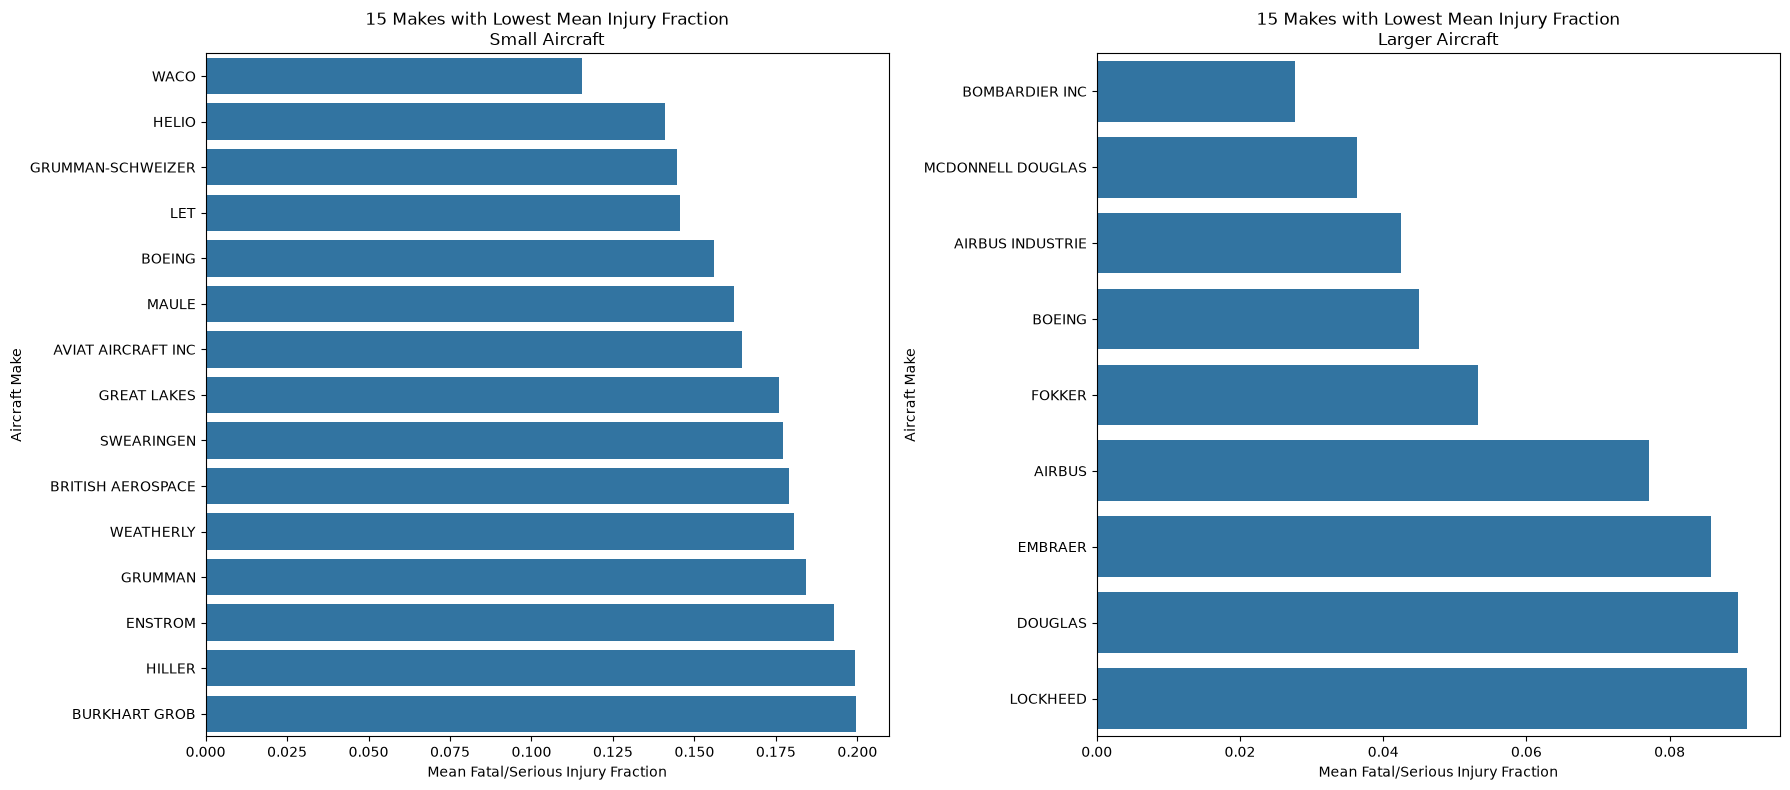

In [36]:
# Plot both groups side-by-side
# Label the groups
small_plot = top15_small_makes.copy()
small_plot["Aircraft.Group"] = "Small Aircraft"

large_plot = top15_large_makes.copy()
large_plot["Aircraft.Group"] = "Larger Aircraft"

# Combine the selected makes
comparison = pd.concat(
    [small_plot, large_plot],
    ignore_index=True
)

# Create a side-by-side comparison
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(18, 8)
)

sns.barplot(
    data=small_plot,
    x="Mean_Injury_Fraction",
    y="Make",
    ax=axes[0]
)

axes[0].set_title(
    "15 Makes with Lowest Mean Injury Fraction\nSmall Aircraft"
)
axes[0].set_xlabel("Mean Fatal/Serious Injury Fraction")
axes[0].set_ylabel("Aircraft Make")

sns.barplot(
    data=large_plot,
    x="Mean_Injury_Fraction",
    y="Make",
    ax=axes[1]
)

axes[1].set_title(
    "15 Makes with Lowest Mean Injury Fraction\nLarger Aircraft"
)
axes[1].set_xlabel("Mean Fatal/Serious Injury Fraction")
axes[1].set_ylabel("Aircraft Make")

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

In [37]:
# Select the ten makes
# Select the ten small-aircraft makes with the lowest mean injury fraction
top10_small_makes = (
    small_make_summary.loc[
        small_make_summary["Accident_Count"]
        >= minimum_group_accidents
    ]
    .nsmallest(10, "Mean_Injury_Fraction")
    .copy()
)

display(top10_small_makes)

,Make,Mean_Injury_Fraction,Accident_Count
94,WACO,0.115497,114
53,HELIO,0.141119,94
51,GRUMMAN-SCHWEIZER,0.144689,91
59,LET,0.145455,110
18,BOEING,0.156084,551
62,MAULE,0.162174,460
12,AVIAT AIRCRAFT INC,0.164474,76
46,GREAT LAKES,0.175926,54
91,SWEARINGEN,0.177319,129
22,BRITISH AEROSPACE,0.179020,50


In [38]:
# Keep only observations belonging to the selected makes
top10_make_names = top10_small_makes["Make"].tolist()

small_top10_data = small_aircraft.loc[
    small_aircraft["Make"].isin(top10_make_names)
].copy()

print("Number of observations:", len(small_top10_data))

display(
    small_top10_data[
        [
            "Make",
            "Fatal.Serious.Injury.Fraction"
        ]
    ].head()
)

Number of observations: 1729


,Make,Fatal.Serious.Injury.Fraction
15,SWEARINGEN,0.00
95,MAULE,0.00
199,MAULE,0.25
247,SWEARINGEN,0.00
255,HELIO,0.00


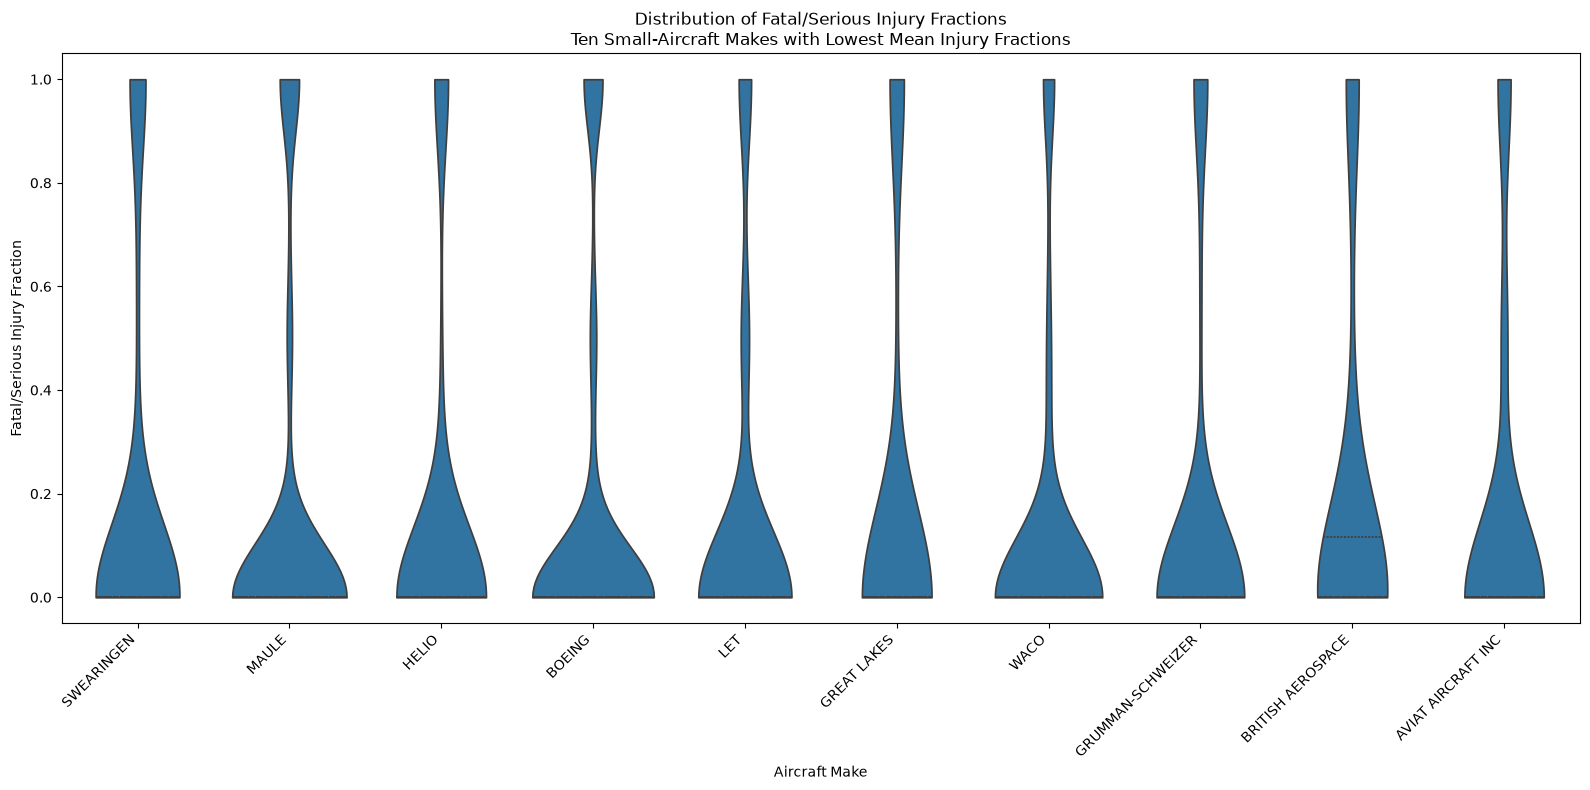

In [39]:
# Create the violin plot
plt.figure(figsize=(16, 8))

sns.violinplot(
    data=small_top10_data,
    x="Make",
    y="Fatal.Serious.Injury.Fraction",
    inner="quartile",
    cut=0
)

plt.title(
    "Distribution of Fatal/Serious Injury Fractions\n"
    "Ten Small-Aircraft Makes with Lowest Mean Injury Fractions"
)

plt.xlabel("Aircraft Make")
plt.ylabel("Fatal/Serious Injury Fraction")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

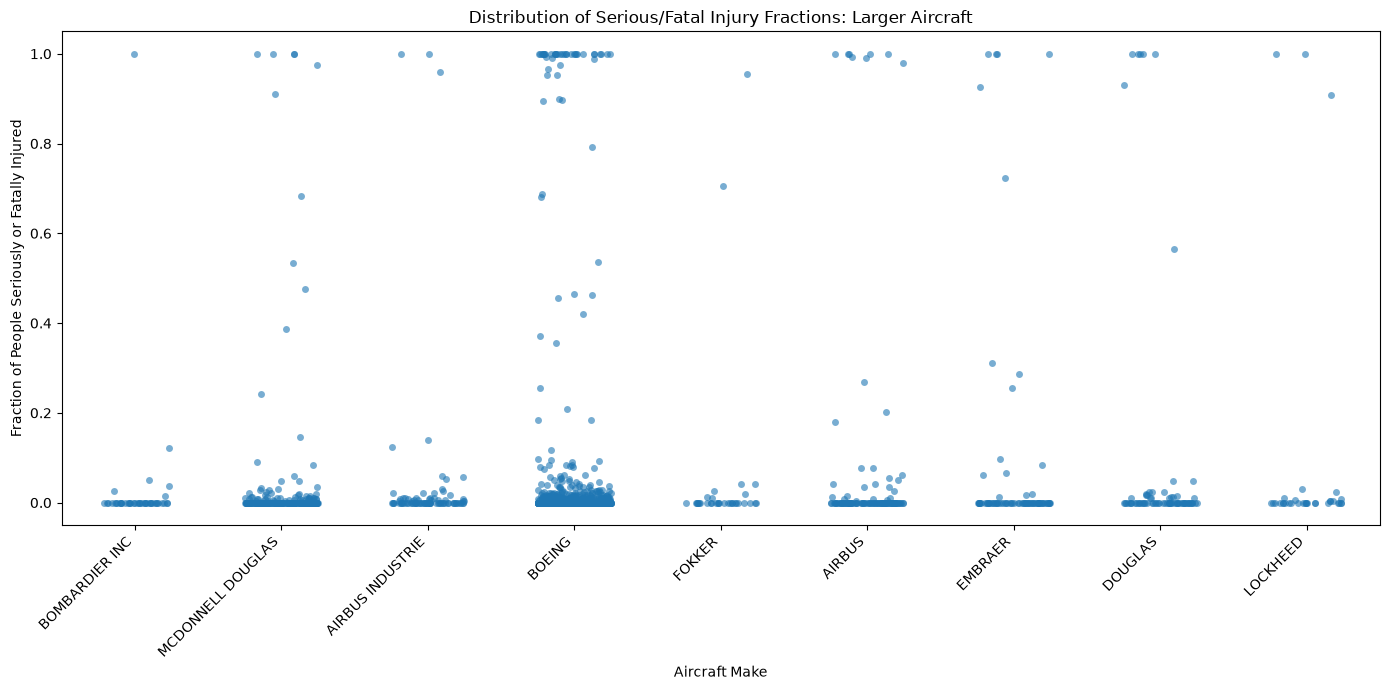

In [40]:
# Summarize injury fractions for larger aircraft by make
large_make_summary = (
    large_aircraft.groupby("Make")["Fatal.Serious.Injury.Fraction"]
    .agg(Mean_Injury_Fraction="mean", Accident_Count="count")
    .reset_index()
)

large_eligible_makes = large_make_summary[
    large_make_summary["Accident_Count"] >= 30
]

# Select ten makes with the lowest mean injury fractions
large_top10_makes = (
    large_eligible_makes
    .nsmallest(10, "Mean_Injury_Fraction")["Make"]
    .tolist()
)

large_top10_data = large_aircraft[
    large_aircraft["Make"].isin(large_top10_makes)
].copy()

large_make_order = (
    large_eligible_makes[
        large_eligible_makes["Make"].isin(large_top10_makes)
    ]
    .sort_values("Mean_Injury_Fraction")["Make"]
    .tolist()
)

plt.figure(figsize=(14, 7))

sns.stripplot(
    data=large_top10_data,
    x="Make",
    y="Fatal.Serious.Injury.Fraction",
    order=large_make_order,
    jitter=0.25,
    alpha=0.6
)

plt.title("Distribution of Serious/Fatal Injury Fractions: Larger Aircraft")
plt.xlabel("Aircraft Make")
plt.ylabel("Fraction of People Seriously or Fatally Injured")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [41]:
def destruction_summary(data):
    # Exclude accidents without a known destruction outcome
    known = data.dropna(subset=["Aircraft.Destroyed"]).copy()

    summary = (
        known.groupby("Make")["Aircraft.Destroyed"]
        .agg(
            Destruction_Fraction="mean",
            Accident_Count="count"
        )
        .reset_index()
    )

    # Require at least 30 known outcomes per make
    summary = summary[
        summary["Accident_Count"] >= 30
    ]

    return summary.sort_values(
        "Destruction_Fraction",
        ascending=True
    )


small_destruction = destruction_summary(small_aircraft)
large_destruction = destruction_summary(large_aircraft)

small_destruction_top15 = small_destruction.head(15)
large_destruction_top15 = large_destruction.head(15)

# Display the summary tables
display(small_destruction_top15)
display(large_destruction_top15)

,Make,Destruction_Fraction,Accident_Count
48,GRUMMAN ACFT ENG COR-SCHWEIZER,0.017241,58
59,LET,0.036364,110
12,AVIAT AIRCRAFT INC,0.040000,75
10,AMERICAN CHAMPION AIRCRAFT,0.040000,50
33,DEHAVILLAND,0.044944,89
34,DIAMOND AIRCRAFT IND INC,0.054054,74
77,ROBINSON HELICOPTER,0.062780,223
42,FLIGHT DESIGN GMBH,0.065217,46
38,ERCOUPE,0.068966,58
50,GRUMMAN AMERICAN AVN. CORP.,0.083333,48


,Make,Destruction_Fraction,Accident_Count
6,BOEING,0.085911,582
21,MCDONNELL DOUGLAS,0.097403,154
3,AIRBUS INDUSTRIE,0.105263,38
15,EMBRAER,0.155556,45
2,AIRBUS,0.160000,50
14,DOUGLAS,0.170213,47


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Findings and Recommendations: Injury and Destruction Rates

The injury-rate plots show differences in the distributions of serious/fatal injury fractions across aircraft makes. The makes with the lowest mean injury fractions are potential candidates for further investigation. However, a low mean does not necessarily mean every accident involving that make had a low injury fraction. The distributions and accident counts must also be considered.

The aircraft destruction analysis provides a second safety measure. A make with both a low serious/fatal injury fraction and a low destruction fraction may warrant further consideration. If a make performs well on one measure but poorly on the other, the results suggest a trade-off that requires further investigation.

The analysis is limited to recorded accidents and therefore does not establish the likelihood of an accident during normal operations. It also does not control for differences in aircraft age, flight hours, operating conditions, accident severity, or the number of flights flown by each make.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

In [42]:
# Model summaries for small aircraft
small_model_summary = (
    small_aircraft.groupby("Make.Model")["Fatal.Serious.Injury.Fraction"]
    .agg(
        Mean_Injury_Fraction="mean",
        Accident_Count="count"
    )
    .reset_index()
)

small_model_summary = small_model_summary[
    small_model_summary["Accident_Count"] >= 10
]

# Model summaries for larger aircraft
large_model_summary = (
    large_aircraft.groupby("Make.Model")["Fatal.Serious.Injury.Fraction"]
    .agg(
        Mean_Injury_Fraction="mean",
        Accident_Count="count"
    )
    .reset_index()
)

large_model_summary = large_model_summary[
    large_model_summary["Accident_Count"] >= 10
]

# Select the ten small-aircraft models with lowest mean injury fractions
small_model_top10 = (
    small_model_summary
    .nsmallest(10, "Mean_Injury_Fraction")
)

# Sort eligible larger models for plotting
large_model_sorted = large_model_summary.sort_values(
    "Mean_Injury_Fraction",
    ascending=True
)

display(small_model_top10)
display(large_model_sorted.head(15))

,Make.Model,Mean_Injury_Fraction,Accident_Count
1828,CESSNA 180C,0.000000,12
2612,DIAMOND AIRCRAFT IND INC DA 20 C1,0.000000,11
3090,GRUMMAN G164B,0.000000,14
4113,PIPER PA-18A 150,0.000000,11
1619,BURKHART GROB G103,0.038462,13
323,AIR TRACTOR AT 602,0.041667,12
2760,ENSTROM F-28A,0.041667,36
4107,PIPER PA-18-180,0.041667,12
5415,WEATHERLY 201B,0.043478,23
2185,CESSNA C172,0.045455,11


,Make.Model,Mean_Injury_Fraction,Accident_Count
242,BOEING 737-800,0.000000,10
631,MCDONNELL DOUGLAS MD-80,0.001385,13
290,BOEING 757,0.001773,24
135,BOEING 727-223,0.002111,14
356,BOEING 787,0.003058,11
239,BOEING 737-7H4,0.003242,12
608,MCDONNELL DOUGLAS DC-9-31,0.003349,12
302,BOEING 757-232,0.003657,17
297,BOEING 757-222,0.003991,16
611,MCDONNELL DOUGLAS DC-9-51,0.004084,10


**Larger planes**

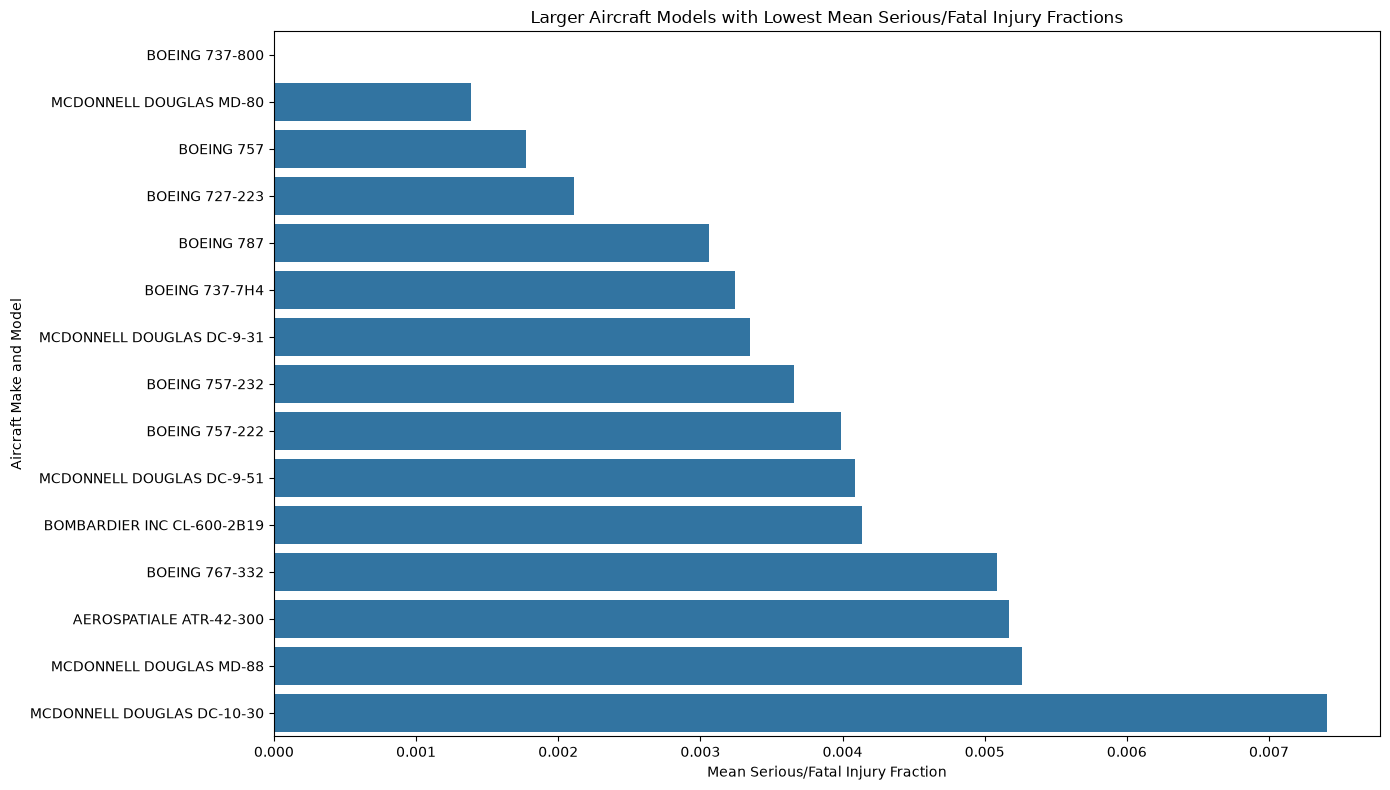

In [43]:
large_models_plot = large_model_sorted.head(15)

plt.figure(figsize=(14, 8))

sns.barplot(
    data=large_models_plot,
    x="Mean_Injury_Fraction",
    y="Make.Model"
)

plt.title("Larger Aircraft Models with Lowest Mean Serious/Fatal Injury Fractions")
plt.xlabel("Mean Serious/Fatal Injury Fraction")
plt.ylabel("Aircraft Make and Model")
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

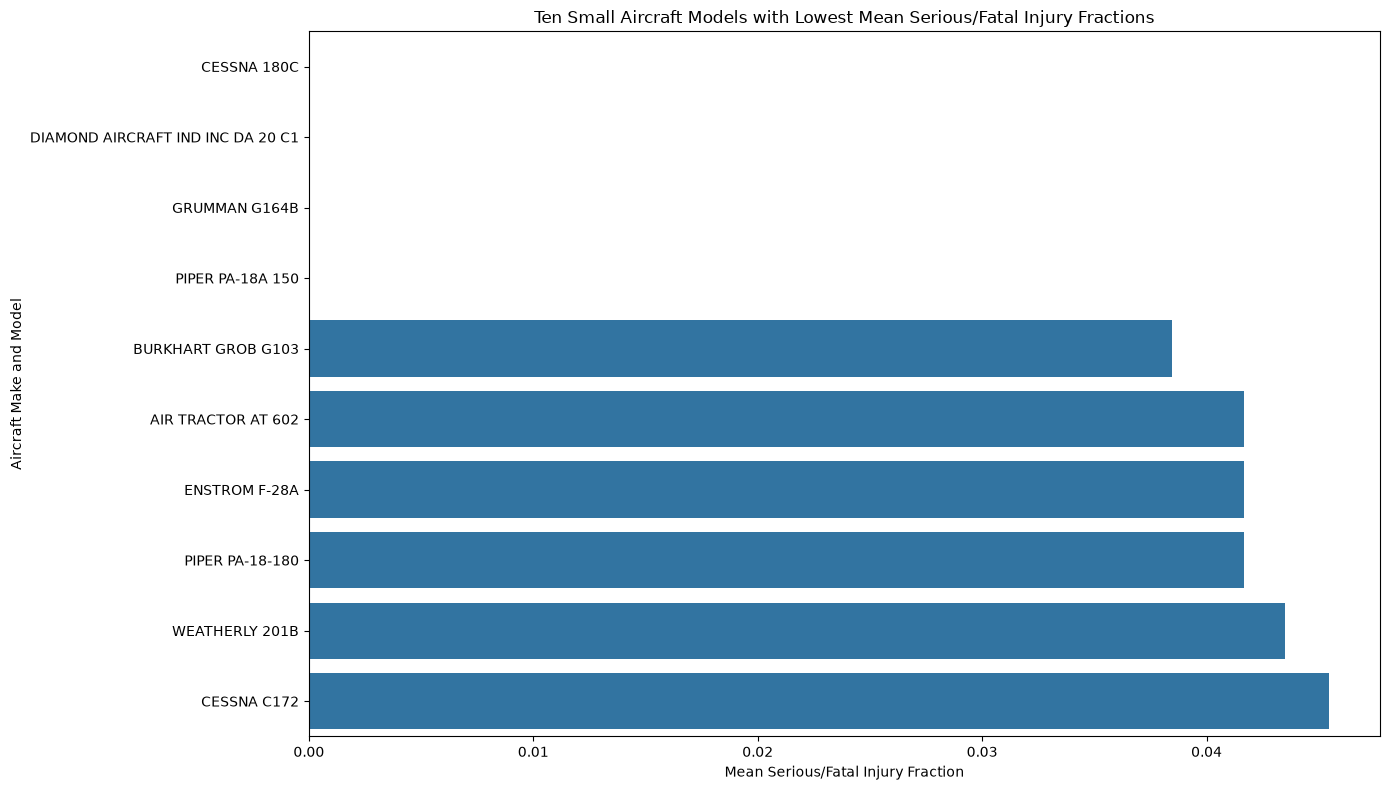

In [44]:
small_models_plot = small_model_top10.sort_values(
    "Mean_Injury_Fraction",
    ascending=True
)

plt.figure(figsize=(14, 8))

sns.barplot(
    data=small_models_plot,
    x="Mean_Injury_Fraction",
    y="Make.Model"
)

plt.title("Ten Small Aircraft Models with Lowest Mean Serious/Fatal Injury Fractions")
plt.xlabel("Mean Serious/Fatal Injury Fraction")
plt.ylabel("Aircraft Make and Model")
plt.tight_layout()
plt.show()

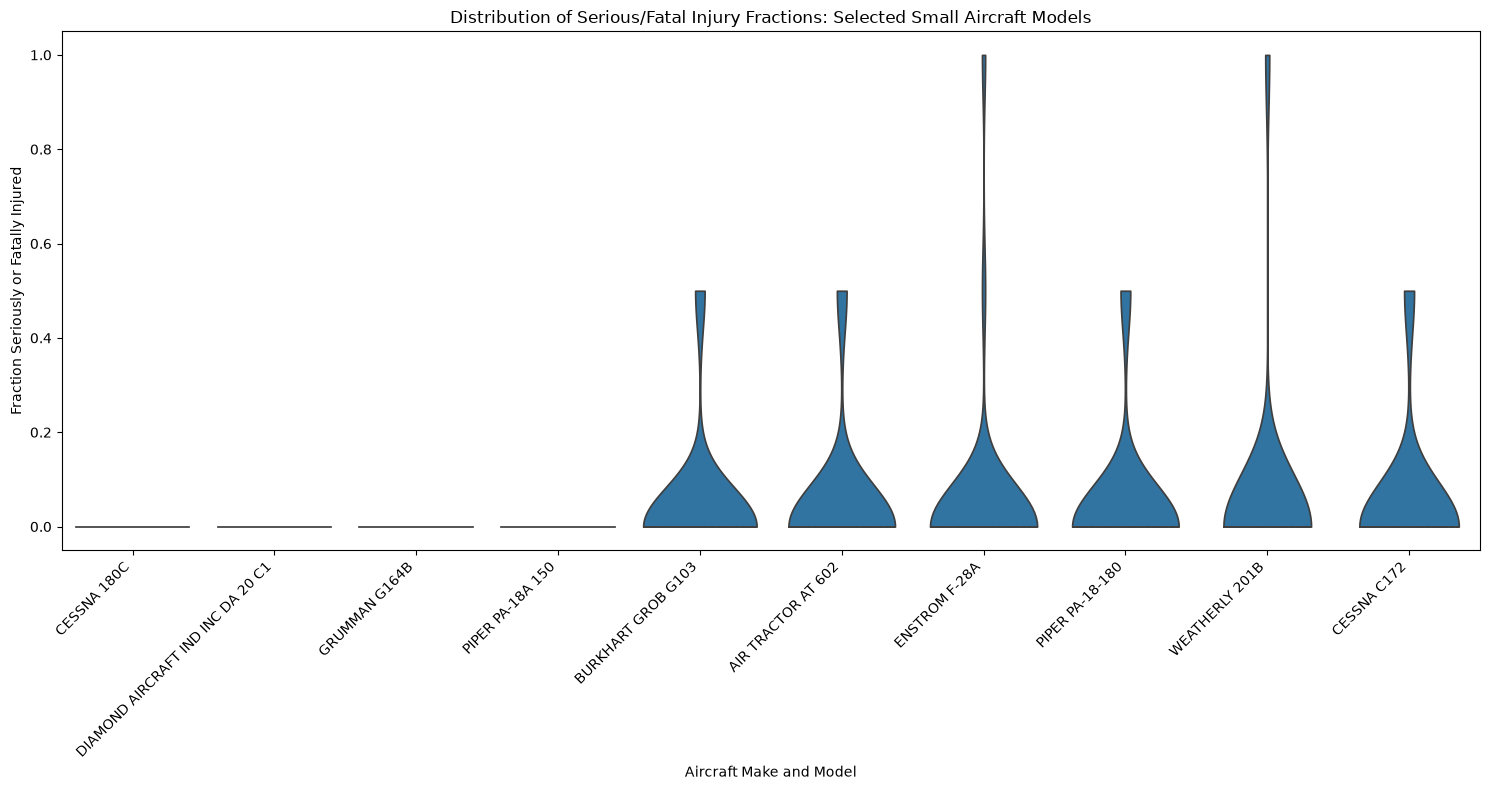

In [45]:
small_model_names = small_model_top10["Make.Model"].tolist()

small_model_data = small_aircraft[
    small_aircraft["Make.Model"].isin(small_model_names)
].copy()

small_model_order = small_model_top10.sort_values(
    "Mean_Injury_Fraction"
)["Make.Model"].tolist()

plt.figure(figsize=(15, 8))

sns.violinplot(
    data=small_model_data,
    x="Make.Model",
    y="Fatal.Serious.Injury.Fraction",
    order=small_model_order,
    inner="quartile",
    cut=0
)

plt.title("Distribution of Serious/Fatal Injury Fractions: Selected Small Aircraft Models")
plt.xlabel("Aircraft Make and Model")
plt.ylabel("Fraction Seriously or Fatally Injured")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

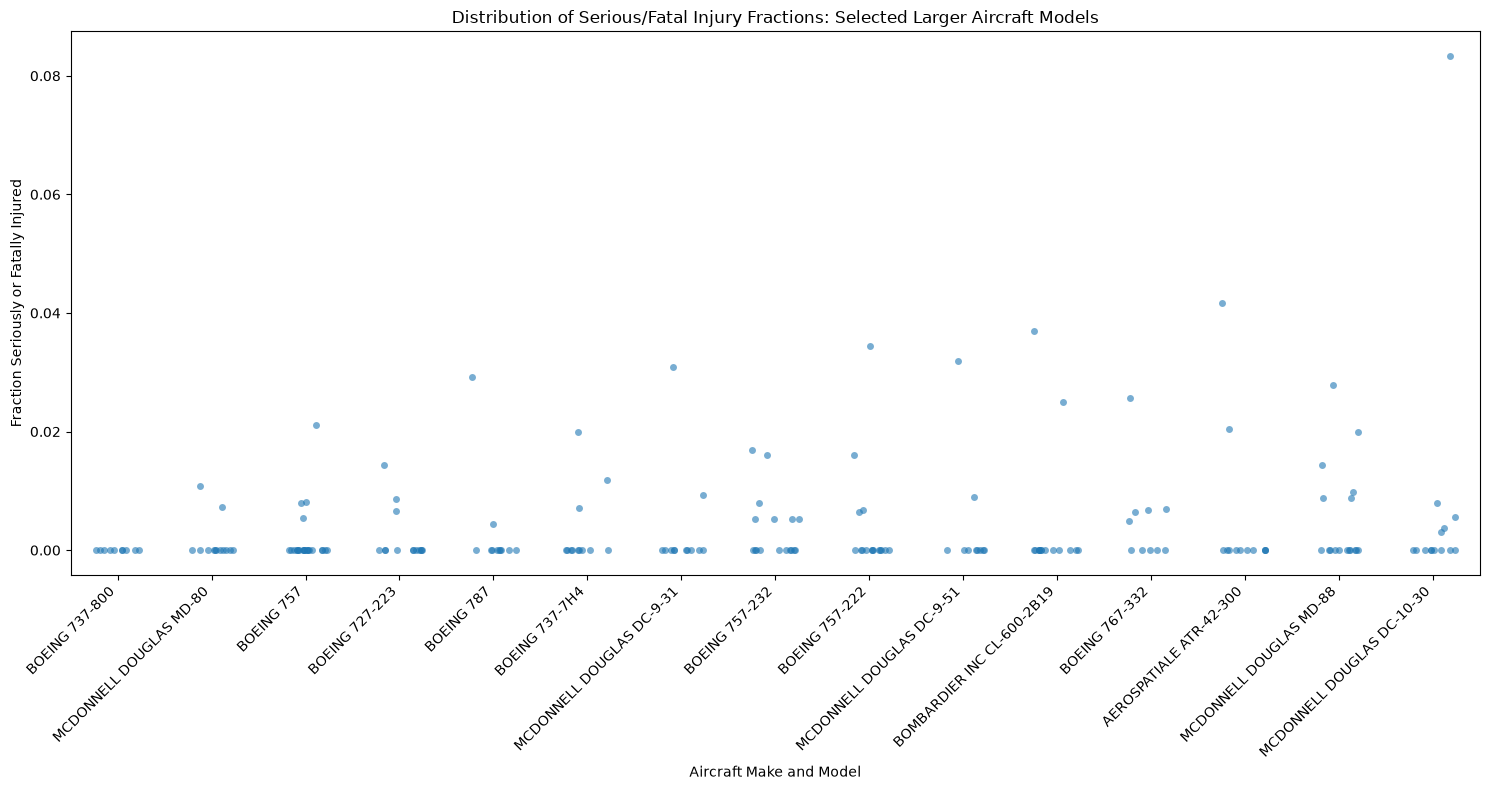

In [46]:
large_model_names = large_models_plot["Make.Model"].tolist()

large_model_data = large_aircraft[
    large_aircraft["Make.Model"].isin(large_model_names)
].copy()

large_model_order = large_models_plot.sort_values(
    "Mean_Injury_Fraction"
)["Make.Model"].tolist()

plt.figure(figsize=(15, 8))

sns.stripplot(
    data=large_model_data,
    x="Make.Model",
    y="Fatal.Serious.Injury.Fraction",
    order=large_model_order,
    jitter=0.25,
    alpha=0.6
)

plt.title("Distribution of Serious/Fatal Injury Fractions: Selected Larger Aircraft Models")
plt.xlabel("Aircraft Make and Model")
plt.ylabel("Fraction Seriously or Fatally Injured")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion of Specific Aircraft Types

The model-level analysis identifies differences in mean serious/fatal injury fractions among the aircraft types represented in the accident dataset. The smaller-aircraft results focus on the ten eligible models with the lowest mean injury fractions, while the larger-aircraft results compare eligible models separately.

The mean values provide a straightforward ranking, but the distribution plots add important context. A model may have a low mean while still having individual accidents with very high injury fractions. A narrower distribution suggests more consistent recorded outcomes, while a wider distribution indicates greater variability.

Models with at least ten accident records were retained, but this threshold alone does not guarantee reliable safety rankings. The analysis includes accidents rather than all flights, and it does not account for the number of flights, flight hours, aircraft age, or operational differences.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

#### Weather Conditions

In [47]:
weather_data = aviation.dropna(
    subset=["Weather.Condition", "Fatal.Serious.Injury.Fraction"]
).copy()

weather_summary = (
    weather_data.groupby("Weather.Condition")
    .agg(
        Accident_Count=("Fatal.Serious.Injury.Fraction", "count"),
        Mean_Injury_Fraction=("Fatal.Serious.Injury.Fraction", "mean")
    )
    .reset_index()
)

# Calculate destruction fraction using known outcomes
weather_destruction = (
    weather_data.dropna(subset=["Aircraft.Destroyed"])
    .groupby("Weather.Condition")["Aircraft.Destroyed"]
    .mean()
    .reset_index(name="Destruction_Fraction")
)

weather_summary = weather_summary.merge(
    weather_destruction,
    on="Weather.Condition",
    how="left"
)

weather_summary = weather_summary[
    weather_summary["Accident_Count"] >= 30
].sort_values("Mean_Injury_Fraction", ascending=False)

display(weather_summary)


,Weather.Condition,Accident_Count,Mean_Injury_Fraction,Destruction_Fraction
0,IMC,4354,0.639546,0.588207
1,UNK,811,0.601303,0.578313
2,VMC,50823,0.226172,0.174915


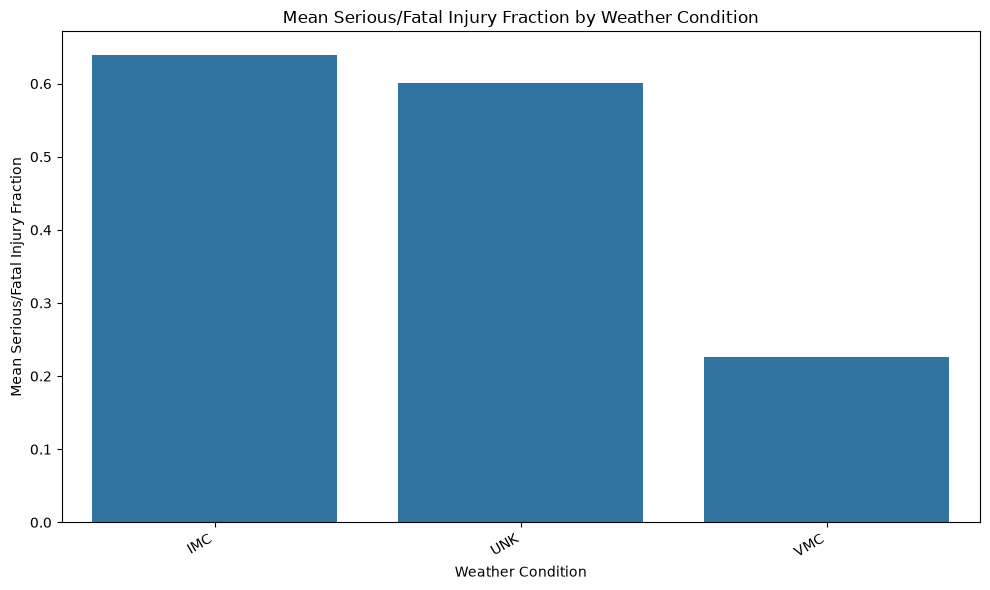

In [48]:
# Plot mean injury fractions by weather condition:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=weather_summary,
    x="Weather.Condition",
    y="Mean_Injury_Fraction"
)

plt.title("Mean Serious/Fatal Injury Fraction by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Mean Serious/Fatal Injury Fraction")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

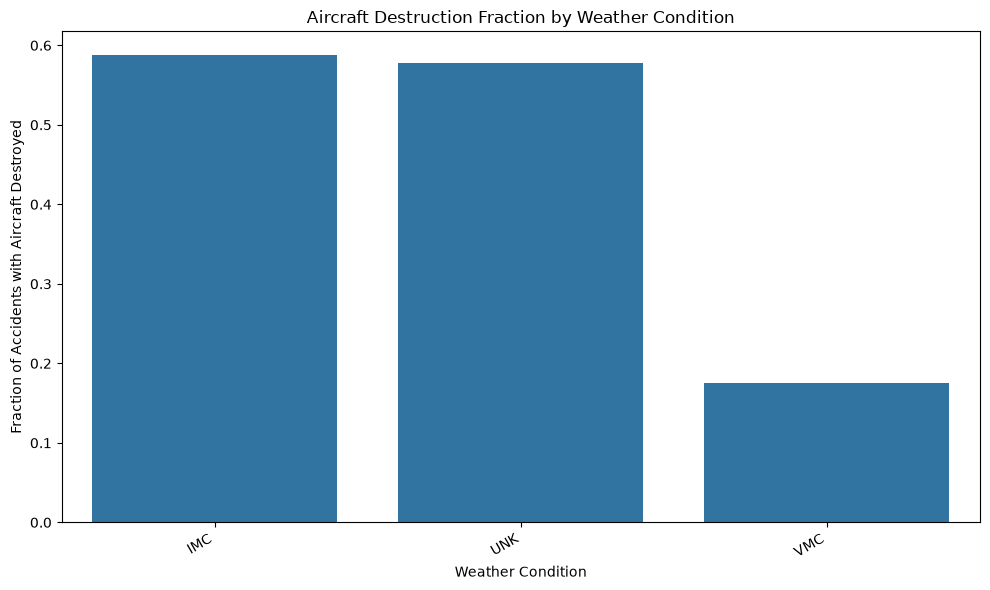

In [49]:
# Plot destruction fractions by weather condition:
weather_destruction_plot = weather_summary.dropna(
    subset=["Destruction_Fraction"]
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=weather_destruction_plot,
    x="Weather.Condition",
    y="Destruction_Fraction"
)

plt.title("Aircraft Destruction Fraction by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Fraction of Accidents with Aircraft Destroyed")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

#### Phase of flight

In [51]:
phase_data = aviation.dropna(
    subset=["Broad.phase.of.flight", "Fatal.Serious.Injury.Fraction"]
).copy()

phase_summary = (
    phase_data.groupby("Broad.phase.of.flight")
    .agg(
        Accident_Count=("Fatal.Serious.Injury.Fraction", "count"),
        Mean_Injury_Fraction=("Fatal.Serious.Injury.Fraction", "mean")
    )
    .reset_index()
)

phase_destruction = (
    phase_data.dropna(subset=["Aircraft.Destroyed"])
    .groupby("Broad.phase.of.flight")["Aircraft.Destroyed"]
    .mean()
    .reset_index(name="Destruction_Fraction")
)

phase_summary = phase_summary.merge(
    phase_destruction,
    on="Broad.phase.of.flight",
    how="left"
)

phase_summary = phase_summary[
    phase_summary["Accident_Count"] >= 30
].sort_values("Mean_Injury_Fraction", ascending=False)

display(phase_summary)

,Broad.phase.of.flight,Accident_Count,Mean_Injury_Fraction,Destruction_Fraction
11,UNKNOWN,345,0.816425,0.763848
6,MANEUVERING,5064,0.463306,0.449166
1,CLIMB,1364,0.386411,0.420641
7,OTHER,67,0.383944,0.328125
2,CRUISE,6828,0.341645,0.362508
0,APPROACH,4155,0.329672,0.308881
3,DESCENT,1263,0.310206,0.323883
4,GO-AROUND,936,0.293314,0.310419
9,TAKEOFF,7900,0.222928,0.231281
8,STANDING,613,0.149625,0.149590


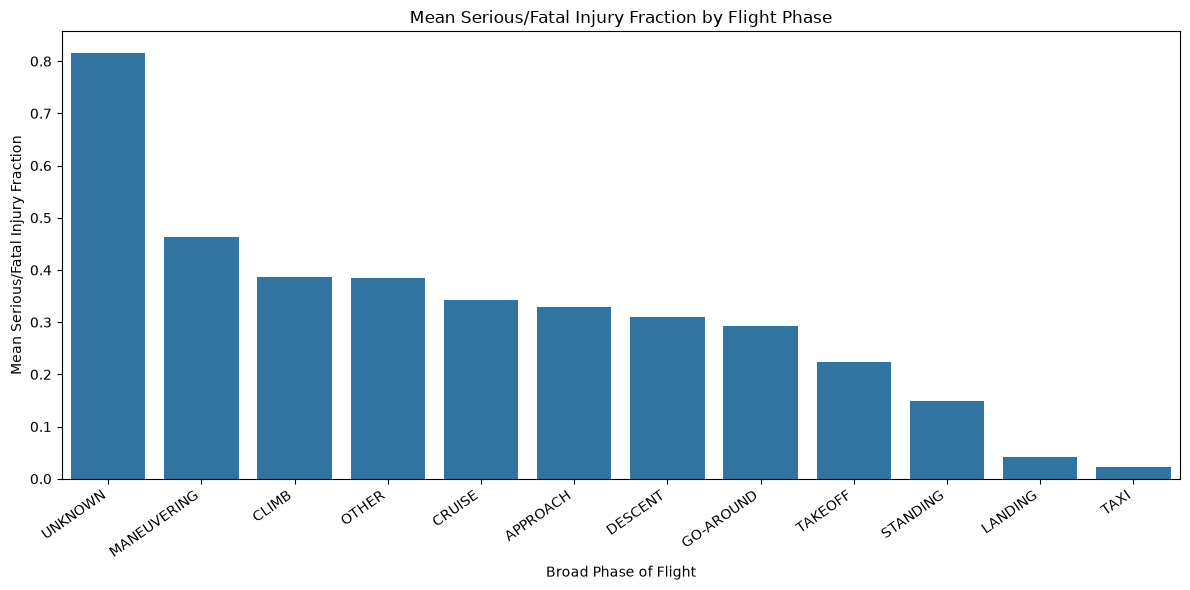

In [52]:
# Plot injury fractions by phase
plt.figure(figsize=(12, 6))

sns.barplot(
    data=phase_summary,
    x="Broad.phase.of.flight",
    y="Mean_Injury_Fraction"
)

plt.title("Mean Serious/Fatal Injury Fraction by Flight Phase")
plt.xlabel("Broad Phase of Flight")
plt.ylabel("Mean Serious/Fatal Injury Fraction")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

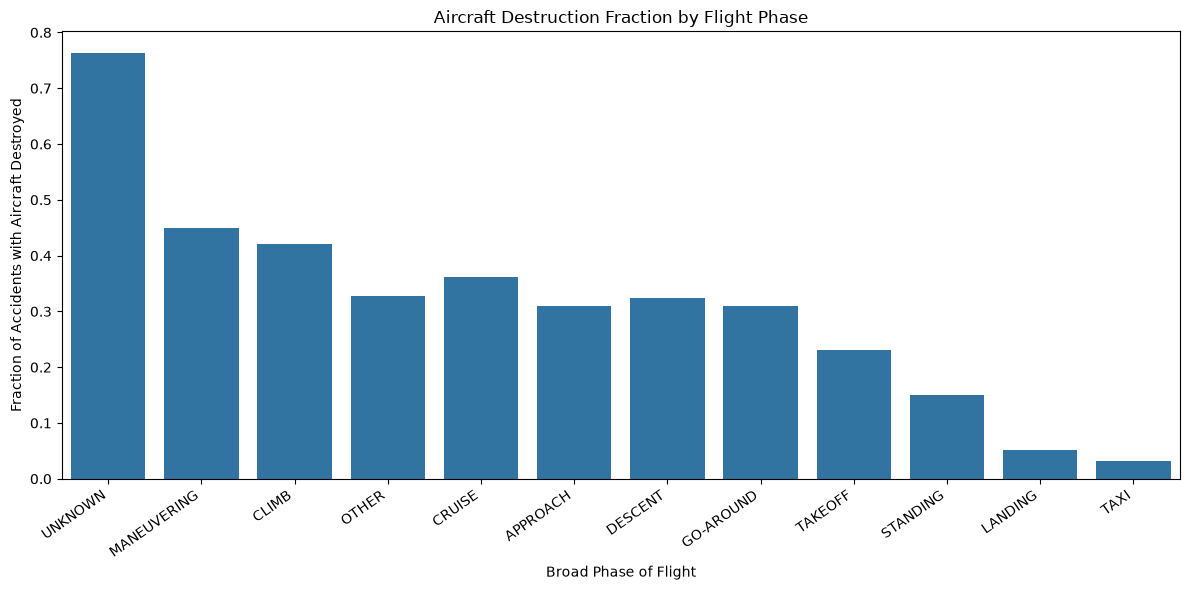

In [53]:
# Plot destruction fractions by phase
phase_destruction_plot = phase_summary.dropna(
    subset=["Destruction_Fraction"]
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=phase_destruction_plot,
    x="Broad.phase.of.flight",
    y="Destruction_Fraction"
)

plt.title("Aircraft Destruction Fraction by Flight Phase")
plt.xlabel("Broad Phase of Flight")
plt.ylabel("Fraction of Accidents with Aircraft Destroyed")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Findings: Weather Condition and Flight Phase

**Weather condition:** The group with the highest mean serious/fatal injury fraction was **[insert condition]**, while **[insert condition]** had the lowest among the groups retained for analysis. The aircraft destruction results showed **[describe the pattern from the table or plot]**. These differences suggest that weather conditions may be associated with different recorded accident outcomes, but the analysis does not establish causation.

**Phase of flight:** The highest mean serious/fatal injury fraction occurred during **[insert phase]**, while **[insert phase]** had the lowest among the eligible groups. The destruction fractions **[describe the observed pattern]**. This indicates that accident outcomes differ across recorded phases of flight and may help identify areas for further safety investigation.

**Limitations:** These statistics are based on recorded accidents, not the total number of flights performed under each weather condition or during each flight phase. Accident counts and the mix of aircraft and circumstances may differ between groups. Further analysis controlling for these differences would be necessary before drawing causal conclusions.